   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

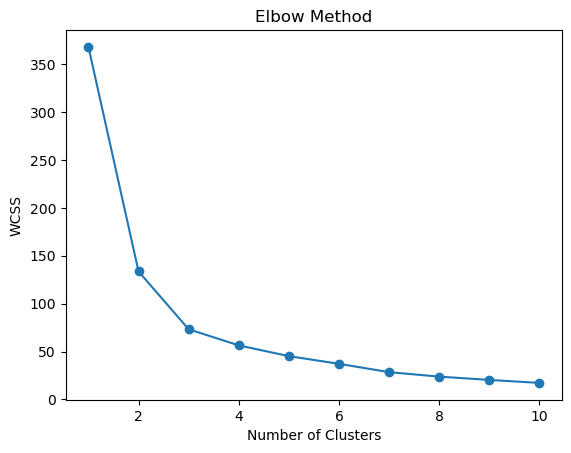

                  Customer  TotalSales  TotalQuantity  AveragePrice  \
0           AV Stores, Co.   157807.81           1778     77.947647   
1             Alpha Cognac    70488.44            687     85.097500   
2       Amica Models & Co.    94117.26            843     85.323462   
3  Anna's Decorations, Ltd   153996.13           1469     83.558043   
4        Atelier graphique    24179.96            270     79.775714   

   OrderCount  Cluster  
0           3        0  
1           3        2  
2           2        2  
3           4        0  
4           3        0  


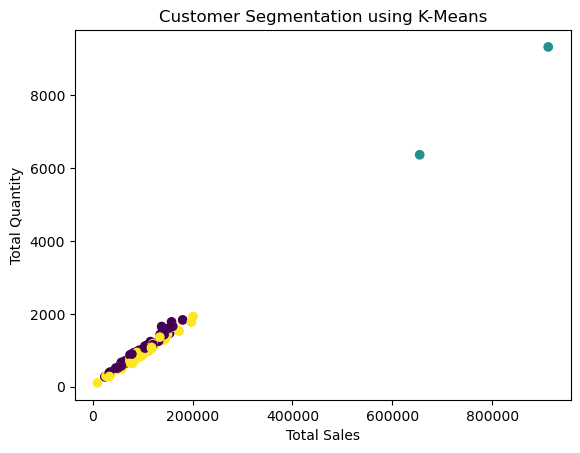

In [1]:
# K-Means Clustering using Sales Data

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Read the dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())

# 2. Group data customer-wise
customer = df.groupby('CUSTOMERNAME').agg({
    'SALES': 'sum',
    'QUANTITYORDERED': 'sum',
    'PRICEEACH': 'mean',
    'ORDERNUMBER': 'nunique'
}).reset_index()

# Rename columns
customer.columns = [
    'Customer', 'TotalSales', 'TotalQuantity',
    'AveragePrice', 'OrderCount'
]

# 3. Select features
X = customer[['TotalSales', 'TotalQuantity',
              'AveragePrice', 'OrderCount']]

# 4. Normalize the data
sc = StandardScaler()
X = sc.fit_transform(X)

# 5. Find the best number of clusters using Elbow Method
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 6. Create K-Means model
km = KMeans(n_clusters=3, random_state=42, n_init=10)

# 7. Fit the model and predict clusters
customer['Cluster'] = km.fit_predict(X)

# 8. Display customer clusters
print(customer.head())

# 9. Plot the clusters
plt.scatter(customer['TotalSales'],
            customer['TotalQuantity'],
            c=customer['Cluster'])

plt.xlabel("Total Sales")
plt.ylabel("Total Quantity")
plt.title("Customer Segmentation using K-Means")
plt.show()